# Physics 1: Lagrangian neural network

*Note (xkan 1.0 port).* Run top to bottom, this notebook learns a Lagrangian close to a quadratic in the velocity (the non-relativistic kinetic energy), where this tutorial's original output showed the relativistic $-\sqrt{1 - v^2}$, so the final formula differs. The original output came from cells run out of order; a search over four seeds and three initialisations (pykan's of August 2024 among them) did not reproduce it.

In [1]:
import torch
from xkan import KANNetwork, create_dataset_from_data, fit
from xkan.utils import batch_jacobian, batch_hessian

torch.use_deterministic_algorithms(True)
torch.set_default_dtype(torch.float64)

seed = 0
torch.manual_seed(seed)

#example = 'harmonic_oscillator'
#example = 'single_pendulum'
example = 'relativistic_mass'

# three examples: harmonic oscillator, single pendulum, double pendulum

# dimension of q
# Lagrangian: (q, qd) -> (qdd)

if example == 'harmonic_oscillator':
    n_sample = 1000
    # harmonic oscillator
    d = 1
    q = torch.rand(size=(n_sample,1)) * 4 - 2
    qd = torch.rand(size=(n_sample,1)) * 4 - 2
    qdd = - q
    x = torch.cat([q, qd], dim=1)
    
if example == 'single_pendulum':
    n_sample = 1000
    # harmonic oscillator
    d = 1
    q = torch.rand(size=(n_sample,1)) * 4 - 2
    qd = torch.rand(size=(n_sample,1)) * 4 - 2
    qdd = - torch.sin(q)
    x = torch.cat([q, qd], dim=1)
    
if example == 'relativistic_mass':
    n_sample = 10000
    # harmonic oscillator
    d = 1
    q = torch.rand(size=(n_sample,1)) * 4 - 2
    #qd = torch.rand(size=(n_sample,1)) * 1.998 - 0.999
    #qd = 0.95 + torch.rand(size=(n_sample,1)) * 0.05
    qd = torch.rand(size=(n_sample,1)) * 2 - 1
    qdd = (1 - qd**2)**(3/2)
    x = torch.cat([q, qd], dim=1)

In [2]:
from xkan.symbolic import compile_formula
from sympy import symbols

input_variables = symbol_x, symbol_vx = symbols('x v_x')
expr = symbol_vx ** 2
model = compile_formula(input_variables, expr, grid=20)

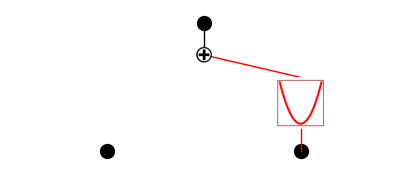

In [3]:
from xkan.viz import plot
plot(model, x);

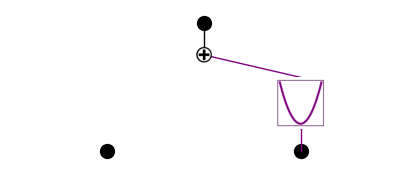

In [4]:
from xkan.interp import perturb
# mode='best' is not a perturb mode (pykan 0.2.8 raised on it too): the default, 'non-intrusive', which switches
# the numeric edges of the last layer on with zero scales
perturb(model, mag=0.1)
plot(model, x);

In [5]:
from tqdm import tqdm
from xkan.nn import update_grids
from xkan.train import LBFGS
from xkan.utils import batch_jacobian, create_dataset_from_data
import numpy as np

torch.use_deterministic_algorithms(True)

def closure():
    
    global loss
    optimizer.zero_grad()
    
    jacobian = batch_jacobian(model, x, create_graph=True)
    hessian = batch_hessian(model, x, create_graph=True)
    Lqdqd = hessian[:,d:,d:]
    Lq = jacobian[:,:d]
    Lqqd = hessian[:,d:,:d]

    Lqqd_qd_prod = torch.einsum('ijk,ik->ij', Lqqd, qd)

    qdd_pred = torch.einsum('ijk,ik->ij', torch.linalg.inv(Lqdqd), Lq - Lqqd_qd_prod)
    loss = torch.mean((qdd - qdd_pred)**2)

    loss.backward()
    return loss

steps = 20
log = 1
optimizer = LBFGS(model.parameters(), lr=1, history_size=10, line_search_fn="strong_wolfe", tolerance_grad=1e-32, tolerance_change=1e-32, tolerance_ys=1e-32)
#optimizer = torch.optim.Adam(params, lr=1e-2)
pbar = tqdm(range(steps), desc='description', ncols=100)


for _ in pbar:
    
    # update grid
    if _ < 5 and _ % 20 == 0:
        update_grids(model, x)
            
    optimizer.step(closure)
    
    if _ % log == 0:
        pbar.set_description("| loss: %.2e |" % loss.cpu().detach().numpy())
        
print("| loss: %.2e |" % loss.cpu().detach().numpy())

| loss: 3.59e-02 |


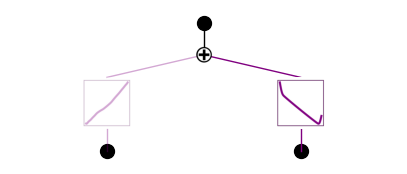

In [6]:
plot(model, x);

In [7]:
from xkan.symbolic import auto_symbolic
auto_symbolic(model, x)

fixing (0,0,0) with x, r2=0.9917987354215777, c=1


fixing (0,1,0) with x, r2=0.961291263821791, c=1


{(0, 0, 0): ('x', np.float64(0.9917987354215777), np.int64(1)),
 (0, 1, 0): ('x', np.float64(0.961291263821791), np.int64(1))}

In [8]:
from xkan.symbolic import suggest_symbolic, unfix_symbolic
unfix_symbolic(model, 0, 0, 0)
suggest_symbolic(model, 0, 0, 0, x)

        function        fitting r2           r2 loss        complexity        total loss
               x          0.991799          -6.92818                 1         -0.585636
           x^0.5          0.997637          -8.71887                 2         -0.143773
            sqrt          0.997637          -8.71887                 2         -0.143773
             log          0.997458          -8.61412                 2         -0.122825
       1/sqrt(x)          0.997383          -8.57257                 2         -0.114514


('x',
 SymbolicFunction(name='x', fn=<function <lambda> at 0x7e7f69eef060>, sympy=<function <lambda> at 0x7e7f69eef100>, complexity=1, singular=<function <lambda> at 0x7e7f69eef1a0>),
 np.float64(0.9917987354215777),
 np.int64(1))

In [9]:
unfix_symbolic(model, 0, 1, 0)
suggest_symbolic(model, 0, 1, 0, x)

        function        fitting r2           r2 loss        complexity        total loss
               0                 0       1.44269e-05                 0       2.88538e-06
               x          0.786795          -2.22962                 1          0.354076
             sin          0.984566          -6.01685                 2          0.396631
             cos          0.984566          -6.01685                 2          0.396631
             x^2           0.98404          -5.96851                 2          0.406298


('0',
 SymbolicFunction(name='0', fn=<function <lambda> at 0x7e7f69f0d940>, sympy=<function <lambda> at 0x7e7f69f0d9e0>, complexity=0, singular=<function <lambda> at 0x7e7f69f0da80>),
 np.float64(0.0),
 np.int64(0))

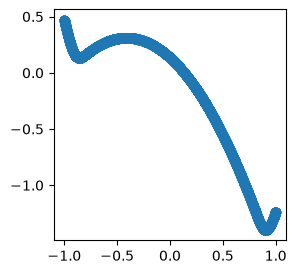

In [10]:
from xkan.viz import plot_edge
x, y = plot_edge(model, x, 0, 1, 0)
x, y = torch.from_numpy(x), torch.from_numpy(y)  # the edge's sorted inputs and outputs, as tensors

In [11]:
from xkan.symbolic import fix_symbolic
from xkan.utils import create_dataset_from_data

train2, test2 = create_dataset_from_data(x[:,None], y[:,None])
model2 = KANNetwork([1, 1, 1])
fix_symbolic(model2, 0, 0, 0, 'x^2', fit=False)

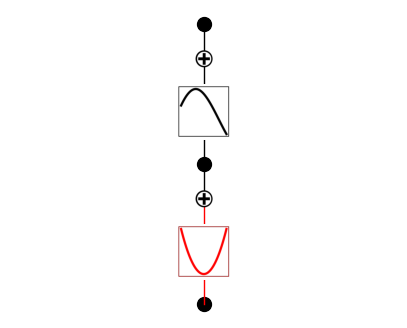

In [12]:
plot(model2, train2['x']);

In [13]:
history = fit(model2, train2, test2, steps=50)
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 0.03094138074668731 test RMSE 0.03090399545195758


In [14]:
history = fit(model2, train2, test2, steps=50, update_grid=False)
print('train RMSE', np.sqrt(history['train/y'][-1]), 'test RMSE', np.sqrt(history['val/y'][-1]))

train RMSE 0.02851781124297793 test RMSE 0.02838764118117946


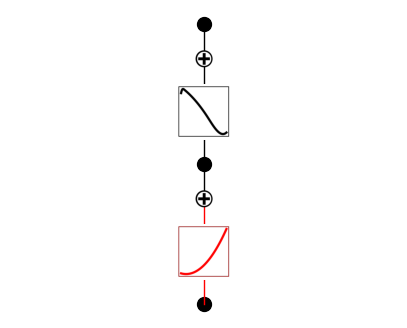

In [15]:
plot(model2, train2['x']);

In [16]:
suggest_symbolic(model2, 1, 0, 0, train2['x'])

        function        fitting r2           r2 loss        complexity        total loss
               x          0.966535          -4.90075                 1         -0.180151
               0                 0       1.44269e-05                 0       2.88538e-06
             cos          0.995463          -7.78085                 2         0.0438292
             sin          0.995463          -7.78085                 2         0.0438292
             x^2          0.976727          -5.42456                 2          0.515088


('x',
 SymbolicFunction(name='x', fn=<function <lambda> at 0x7e7f69eef060>, sympy=<function <lambda> at 0x7e7f69eef100>, complexity=1, singular=<function <lambda> at 0x7e7f69eef1a0>),
 np.float64(0.9665345709842691),
 np.int64(1))

In [17]:
from xkan.symbolic import fit_params
fit_params(x**2, y, lambda x: x**(1/2))

r2 is 0.21305651819892574
r2 is not very high, please double check if you are choosing the correct symbolic function.


(tensor([ 8.3194,  1.0164, -0.4094,  0.5647]), tensor(0.2131))

In [18]:
auto_symbolic(model2, train2['x'])

skipping (0,0,0) since already symbolic


fixing (1,0,0) with x, r2=0.9665345709842691, c=1


{(1, 0, 0): ('x', np.float64(0.9665345709842691), np.int64(1))}

In [19]:
from sympy import expand
from xkan.symbolic import symbolic_formula
from xkan.utils import ex_round
ex_round(expand(symbolic_formula(model2)[0][0]), 2)

-0.58*x_1**2 - 0.91*x_1 + 0.01